# Prediksi Pembatalan Reservasi Hotel dengan Random Forest dan XGBoost Manual

**Kelompok 3 · Perdagangan Elektronik dan Intelligent Bisnis · Informatika Universitas Udayana**
I Gusti Ayu Riyani Astarani (2308561033) · I Gusti Ayu Riyana Astarani (2308561031)

Notebook ini mengikuti tahapan **CRISP-DM** dan seluruh algoritma ditulis **manual tanpa scikit-learn maupun library xgboost**.
Library yang dipakai hanya `numpy` (perhitungan), `pandas` (membaca tabel), dan `matplotlib` (grafik).

Isi notebook:
1. Data Understanding: karakteristik data sebagai alasan pemilihan metode
2. Data Preparation: pembersihan data dan encoding manual
3. Modeling: Decision Tree (Gini), Random Forest, dan XGBoost manual, termasuk pre-pruning dan post-pruning
4. Evaluation: accuracy, precision, recall, F1-score, confusion matrix, perbandingan dengan baseline, perbandingan pembagian data
5. Explainability: SHAP manual (metode permutasi Shapley)
6. Deployment: tahapan penerapan ke aplikasi web HotelGuard

In [1]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
UNGU, PINK, ABU = '#6C4CF1', '#E85D9A', '#A3A1B5'
HASIL = Path('hasil'); HASIL.mkdir(exist_ok=True)

def persen(x, d=2):
    return f'{x:.{d}f}%'.replace('.', ',')

def ribuan(x):
    return f'{int(x):,}'.replace(',', '.')

## 1. Data Understanding

Dataset **Hotel Booking Demand** (Antonio, Almeida, Nunes, 2019) berisi 119.390 reservasi dari City Hotel dan Resort Hotel di Portugal
dengan 32 kolom. Label yang diprediksi adalah `is_canceled` (1 = batal, 0 = tidak batal).

In [2]:
raw = pd.read_csv('../backend/data/hotel_bookings.csv')
print('Ukuran data mentah:', raw.shape)
raw.head(10)

Ukuran data mentah: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


In [3]:
tipe = pd.Series(['numerik' if pd.api.types.is_numeric_dtype(raw[c]) else 'kategorikal' for c in raw.columns]).value_counts()
print(tipe.to_string())
print()
print('Proporsi label is_canceled:')
print((raw['is_canceled'].value_counts(normalize=True) * 100).round(1).to_string())
print()
print('Missing value terbanyak:')
print(raw.isna().sum().sort_values(ascending=False).head(4).to_string())

numerik        20
kategorikal    12

Proporsi label is_canceled:
is_canceled
0    63.0
1    37.0

Missing value terbanyak:
company     112593
agent        16340
country        488
children         4


### Karakteristik data dan alasan pemilihan metode

| Karakteristik | Temuan | Konsekuensi pada metode |
|---|---|---|
| Bentuk data | Tabular, campuran kolom numerik dan kategorikal | Model berbasis pohon cocok: tidak butuh scaling dan bisa memakai hasil One-Hot Encoding |
| Keseimbangan kelas | Batal sekitar 28% setelah dibersihkan (tidak seimbang) | Perlu bobot kelas (`class_weight` di RF, `scale_pos_weight` di XGBoost) dan evaluasi memakai F1, bukan accuracy saja |
| Hubungan fitur dengan label | Tidak linear (contoh: lead time pendek jarang batal, lead time panjang sering batal) | Pohon keputusan mampu menangkap pola tidak linear dan interaksi antarfitur |
| Jumlah data | Puluhan ribu baris | Cukup untuk model ensemble (banyak pohon) |
| Kebutuhan bisnis | Hotel perlu tahu alasan prediksi | Ditambah SHAP agar model tidak menjadi kotak hitam |

Karena itu dipilih dua algoritma ensemble berbasis pohon dengan pendekatan berbeda:
**Random Forest** (bagging, pohon dilatih paralel) dan **XGBoost** (boosting, pohon dilatih berurutan).

## 2. Data Preparation

Fungsi di bawah adalah fungsi yang **sama persis** dengan modul `backend/ml/preprocessing.py` di aplikasi,
sehingga hasil notebook dan aplikasi konsisten.

**Cara mengubah data menjadi angka (encoding):**
- Fitur numerik (lead_time, adr, dll.) dipakai apa adanya.
- Fitur biner (is_repeated_guest, punya_company) bernilai 0/1.
- Fitur ordinal `arrival_date_month` diubah menjadi angka 1 sampai 12 sesuai urutan bulan.
- Fitur nominal (hotel, meal, country, market_segment, distribution_channel, reserved_room_type, deposit_type, customer_type, agent)
  diubah dengan **One-Hot Encoding manual** (`drop_first`: satu kategori dijadikan acuan agar tidak redundan).
  Untuk `country` dan `agent` hanya 15 kategori teratas yang dipertahankan, sisanya digabung menjadi `Lainnya`.
- Encoder di-*fit* **hanya pada data latih** lalu diterapkan ke data uji, sehingga tidak ada kebocoran informasi dari data uji.

In [4]:
"""
Preprocessing data Hotel Booking Demand (tanpa scikit-learn).

Dua tahap:
1. clean_raw()  : membersihkan data mentah (32 kolom) menjadi data bersih yang
                  masih mudah dibaca (21 fitur + tahun kedatangan + label).
2. Encoder      : mengubah data bersih menjadi matriks angka (68 kolom) untuk model.
                  Encoder di-fit HANYA pada data latih agar tidak terjadi kebocoran data.
"""
import numpy as np
import pandas as pd

BULAN = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
         'August', 'September', 'October', 'November', 'December']

# Kolom yang wajib ada pada data mentah
RAW_REQUIRED = [
    'hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month',
    'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
    'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest',
    'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type',
    'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr',
    'required_car_parking_spaces', 'total_of_special_requests',
]

# Kolom kebocoran data (baru diketahui setelah status reservasi terjadi)
LEAKAGE = ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes']

FITUR_NUMERIK = ['lead_time', 'adr', 'total_malam', 'total_tamu', 'previous_cancellations',
                 'previous_bookings_not_canceled', 'days_in_waiting_list',
                 'required_car_parking_spaces', 'total_of_special_requests']
FITUR_BINER = ['is_repeated_guest', 'punya_company']
FITUR_ORDINAL = ['arrival_date_month']
FITUR_NOMINAL = ['hotel', 'meal', 'country', 'market_segment', 'distribution_channel',
                 'reserved_room_type', 'deposit_type', 'customer_type', 'agent']
FITUR = FITUR_NUMERIK + FITUR_BINER + FITUR_ORDINAL + FITUR_NOMINAL          # 21 fitur
LABEL = 'is_canceled'
CLEAN_COLS = ['arrival_date_year'] + FITUR + [LABEL]                         # 23 kolom


def is_clean(df: pd.DataFrame) -> bool:
    """Data dianggap sudah bersih jika kolomnya persis format data bersih."""
    return set(df.columns) == set(CLEAN_COLS)


def is_raw(df: pd.DataFrame) -> bool:
    return all(c in df.columns for c in RAW_REQUIRED)


def clean_raw(df: pd.DataFrame):
    """Membersihkan data mentah. Mengembalikan (data_bersih, laporan_langkah)."""
    d = df.copy()
    laporan = []
    n0, k0 = d.shape

    # 1. Hapus kolom kebocoran data
    bocor = [c for c in LEAKAGE if c in d.columns]
    d = d.drop(columns=bocor)
    laporan.append(dict(judul='Hapus kolom kebocoran data',
                        detail=', '.join(bocor) if bocor else 'tidak ada kolom kebocoran',
                        hasil=f'{len(bocor)} kolom'))

    # 2. Isi missing value
    n_missing = int(d[['company', 'agent', 'country', 'children']].isna().sum().sum())
    d['punya_company'] = d['company'].notna().astype(int)
    d = d.drop(columns=['company'])
    d['agent'] = d['agent'].fillna(0).astype(int)
    d['country'] = d['country'].fillna('Unknown')
    d['children'] = d['children'].fillna(0).astype(int)
    laporan.append(dict(judul='Isi missing value',
                        detail='company jadi flag punya_company, agent jadi 0, country jadi Unknown, children jadi 0',
                        hasil=f'{n_missing:,} sel'.replace(',', '.')))

    # 3. Hapus data tidak wajar
    tamu = d['adults'] + d['children'] + d['babies']
    buang = (tamu <= 0) | (d['adr'] < 0) | (d['adr'] > 1000)
    d = d[~buang]
    laporan.append(dict(judul='Hapus data tidak wajar',
                        detail='Reservasi tanpa tamu dan ADR di luar 0 sampai 1.000',
                        hasil=f'{int(buang.sum()):,} baris'.replace(',', '.')))

    # 4. Rapikan kategori
    d['meal'] = d['meal'].replace('Undefined', 'SC')
    undef = (d['market_segment'] == 'Undefined') | (d['distribution_channel'] == 'Undefined')
    d = d[~undef]
    laporan.append(dict(judul='Rapikan kategori',
                        detail='meal Undefined jadi SC, segmen/channel Undefined dihapus',
                        hasil=f'{int(undef.sum())} baris'))

    # 5. Gabungkan tipe kamar langka
    vc = d['reserved_room_type'].value_counts()
    langka = list(vc[vc < 100].index)
    d['reserved_room_type'] = d['reserved_room_type'].where(~d['reserved_room_type'].isin(langka), 'Lainnya')
    laporan.append(dict(judul='Gabungkan tipe kamar langka',
                        detail='Tipe kamar dengan kurang dari 100 data jadi Lainnya',
                        hasil=f'{len(langka)} kategori'))

    # 6. Hapus duplikat
    n_sebelum = len(d)
    d = d.drop_duplicates(keep='first')
    laporan.append(dict(judul='Hapus data duplikat', detail='Baris yang identik di semua kolom',
                        hasil=f'{n_sebelum - len(d):,} baris'.replace(',', '.')))

    # 7. Feature engineering
    d['total_malam'] = d['stays_in_weekend_nights'] + d['stays_in_week_nights']
    d['total_tamu'] = d['adults'] + d['children'] + d['babies']
    d['arrival_date_month'] = d['arrival_date_month'].map({b: i for i, b in enumerate(BULAN, 1)})
    d['agent'] = d['agent'].astype(str).replace({'0': 'Tanpa agen'})
    laporan.append(dict(judul='Feature engineering',
                        detail='total_malam, total_tamu, bulan diubah jadi angka 1 sampai 12',
                        hasil='2 fitur baru'))

    d = d[CLEAN_COLS].reset_index(drop=True)

    # 8. Encoding (dilakukan saat training, dicatat agar pengguna tahu bentuk akhirnya)
    enc = Encoder().fit(d)
    laporan.append(dict(judul='Encoding',
                        detail='One-Hot Encoding 9 fitur kategori (country dan agent: 15 teratas + Lainnya)',
                        hasil=f'{len(enc.columns)} fitur'))

    info = dict(baris_awal=int(n0), kolom_awal=int(k0), baris_bersih=int(len(d)),
                kolom_bersih=int(d.shape[1]), kolom_model=int(len(enc.columns) + 1),
                persen_batal=round(float(d[LABEL].mean() * 100), 2))
    return d, laporan, info


class Encoder:
    """One-Hot Encoding manual (drop_first) + pengelompokan 15 kategori teratas."""

    def __init__(self, top_n=15):
        self.top_n = top_n

    def fit(self, d: pd.DataFrame):
        self.kategori = {}
        self.top = {}
        for c in FITUR_NOMINAL:
            s = d[c].astype(str)
            if c in ('country', 'agent'):
                top = list(s.value_counts().head(self.top_n).index)
                s = s.where(s.isin(top), 'Lainnya')
                self.top[c] = top
            cats = sorted(s.unique())
            self.kategori[c] = cats[1:]          # drop_first: kategori pertama jadi acuan
        self.columns = (FITUR_NUMERIK + FITUR_BINER + FITUR_ORDINAL +
                        [f'{c}_{k}' for c in FITUR_NOMINAL for k in self.kategori[c]])
        # kelompok kolom per fitur asal (untuk SHAP)
        self.groups = []
        for f in FITUR:
            idx = [i for i, col in enumerate(self.columns) if col == f or col.startswith(f + '_') and f in FITUR_NOMINAL]
            self.groups.append((f, np.array(idx)))
        return self

    def transform(self, d: pd.DataFrame) -> np.ndarray:
        n = len(d)
        X = np.zeros((n, len(self.columns)), dtype=np.float32)
        j = 0
        for c in FITUR_NUMERIK + FITUR_BINER + FITUR_ORDINAL:
            X[:, j] = d[c].to_numpy(dtype=np.float32)
            j += 1
        for c in FITUR_NOMINAL:
            s = d[c].astype(str)
            if c in self.top:
                s = s.where(s.isin(self.top[c]), 'Lainnya')
            v = s.to_numpy()
            for k in self.kategori[c]:
                X[:, j] = (v == k)
                j += 1
        return X

In [5]:
data, laporan, info = clean_raw(raw)
pd.DataFrame(laporan).rename(columns={'judul': 'Langkah', 'detail': 'Keterangan', 'hasil': 'Hasil'})

,Langkah,Keterangan,Hasil
0,Hapus kolom kebocoran data,"reservation_status, reservation_status_date, a...",4 kolom
1,Isi missing value,"company jadi flag punya_company, agent jadi 0,...",129.425 sel
2,Hapus data tidak wajar,Reservasi tanpa tamu dan ADR di luar 0 sampai ...,182 baris
3,Rapikan kategori,"meal Undefined jadi SC, segmen/channel Undefin...",5 baris
4,Gabungkan tipe kamar langka,Tipe kamar dengan kurang dari 100 data jadi La...,1 kategori
5,Hapus data duplikat,Baris yang identik di semua kolom,34.041 baris
6,Feature engineering,"total_malam, total_tamu, bulan diubah jadi ang...",2 fitur baru
7,Encoding,One-Hot Encoding 9 fitur kategori (country dan...,68 fitur


In [6]:
print(f"Sebelum : {ribuan(info['baris_awal'])} baris x {info['kolom_awal']} kolom")
print(f"Sesudah : {ribuan(info['baris_bersih'])} baris x {info['kolom_bersih']} kolom (21 fitur + tahun + label)")
print(f"Masuk model: {info['kolom_model'] - 1} kolom fitur hasil encoding + 1 label")
print(f"Proporsi batal: {persen(info['persen_batal'], 1)}")
data.head()

Sebelum : 119.390 baris x 32 kolom
Sesudah : 85.162 baris x 23 kolom (21 fitur + tahun + label)
Masuk model: 68 kolom fitur hasil encoding + 1 label
Proporsi batal: 27,7%


,arrival_date_year,lead_time,adr,total_malam,total_tamu,previous_cancellations,previous_bookings_not_canceled,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,...,hotel,meal,country,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type,agent,is_canceled
0,2015,342,0.0,0,2,0,0,0,0,0,...,Resort Hotel,BB,PRT,Direct,Direct,C,No Deposit,Transient,Tanpa agen,0
1,2015,737,0.0,0,2,0,0,0,0,0,...,Resort Hotel,BB,PRT,Direct,Direct,C,No Deposit,Transient,Tanpa agen,0
2,2015,7,75.0,1,1,0,0,0,0,0,...,Resort Hotel,BB,GBR,Direct,Direct,A,No Deposit,Transient,Tanpa agen,0
3,2015,13,75.0,1,1,0,0,0,0,0,...,Resort Hotel,BB,GBR,Corporate,Corporate,A,No Deposit,Transient,304,0
4,2015,14,98.0,2,2,0,0,0,0,1,...,Resort Hotel,BB,GBR,Online TA,TA/TO,A,No Deposit,Transient,240,0


## 3. Modeling: algoritma manual

Semua algoritma ada di sel-sel berikut. Setiap sel sama persis dengan satu file di folder `backend/ml/` (evaluasi, pohon keputusan, Random Forest, XGBoost, SHAP).

### Fungsi yang dipakai di awal dan di akhir

| | Di awal (membangun model) | Di akhir (menghasilkan prediksi) |
|---|---|---|
| **Decision Tree** | **Gini impurity** = 1 - p<sub>batal</sub><sup>2</sup> - p<sub>tidak</sub><sup>2</sup>; split dipilih yang paling menurunkan Gini | Probabilitas batal = proporsi batal di daun |
| **Random Forest** | Bootstrap sampling + subset fitur acak (sqrt dari jumlah fitur), tiap pohon memakai Gini | **Voting**: rata-rata probabilitas semua pohon, batal jika >= 0,5 |
| **XGBoost** | Skor awal = log-odds proporsi batal. Tiap pohon dibangun dari **gradien** g = p - y dan **hessian** h = p(1 - p) fungsi **log-loss**. Gain = 0,5 [G<sub>L</sub><sup>2</sup>/(H<sub>L</sub>+λ) + G<sub>R</sub><sup>2</sup>/(H<sub>R</sub>+λ) - G<sup>2</sup>/(H+λ)] | Skor total (log-odds) diubah menjadi probabilitas dengan **fungsi sigmoid** σ(z) = 1 / (1 + e<sup>-z</sup>), batal jika >= 0,5 |

### Pre-pruning dan post-pruning

| | Pre-pruning (membatasi saat pohon dibangun) | Post-pruning (memangkas setelah pohon jadi) |
|---|---|---|
| **Random Forest** | `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features` | `ccp_alpha` (cost complexity pruning): cabang yang perbaikan impurity-nya per daun lebih kecil dari alpha dipangkas |
| **XGBoost** | `max_depth`, `min_child_weight` (minimal jumlah hessian di anak) | `gamma`: pohon dibangun penuh, lalu split dengan gain lebih kecil dari gamma dipangkas dari bawah ke atas |

**Yang dipakai di model final** (hasil tuning bagian 3.3):
- XGBoost: pre-pruning `max_depth` = 8 dan `min_child_weight` = 3; post-pruning `gamma` = 5.
- Random Forest: pre-pruning `max_depth` = 25, `min_samples_split` = 5, `min_samples_leaf` = 1, `max_features` = sqrt; post-pruning `ccp_alpha` = 0,00005.

Agar cepat, nilai tiap fitur dikelompokkan ke maksimal 32 bin (teknik histogram yang juga dipakai XGBoost asli).

#### 3.0a Pembagian data dan metrik evaluasi (`ml/evaluasi.py`)

In [7]:
# === backend/ml/evaluasi.py ===
"""
Pembagian data dan metrik evaluasi (manual).

- stratified_split : membagi data latih/uji dengan proporsi kelas batal yang sama
- hitung_metrik    : confusion matrix (TN, FP, FN, TP), accuracy, precision, recall, F1-score
"""
import numpy as np


# Pembagian data
def stratified_split(y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)
    idx_latih, idx_uji = [], []
    for kelas in np.unique(y):
        idx = np.where(y == kelas)[0]
        rng.shuffle(idx)
        n_uji = int(round(len(idx) * test_size))
        idx_uji.append(idx[:n_uji])
        idx_latih.append(idx[n_uji:])
    latih = np.concatenate(idx_latih)
    uji = np.concatenate(idx_uji)
    rng.shuffle(latih)
    rng.shuffle(uji)
    return latih, uji


# Metrik evaluasi
def hitung_metrik(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(accuracy=acc * 100, precision=prec * 100, recall=rec * 100, f1=f1 * 100,
                tn=tn, fp=fp, fn=fn, tp=tp)


#### 3.0b Pohon keputusan dengan Gini impurity (`ml/pohon_keputusan.py`)
Dasar Random Forest. Berisi pre-pruning dan post-pruning (`ccp_alpha`).

In [8]:
# === backend/ml/pohon_keputusan.py ===
"""
Pohon keputusan (Decision Tree) manual dengan Gini impurity, dasar dari Random Forest.

- Binner          : mengelompokkan nilai tiap fitur ke maksimal 32 bin (histogram) agar pencarian split cepat
- prediksi_pohon  : menelusuri pohon untuk banyak baris sekaligus (dipakai Random Forest dan XGBoost)
- DecisionTreeGini:
    Fungsi di awal : Gini impurity = 1 - p_batal^2 - p_tidak^2, split dipilih yang paling menurunkan Gini
    Fungsi di akhir: probabilitas batal = proporsi batal di daun
    Pre-pruning    : max_depth, min_samples_split, min_samples_leaf, max_features, min_impurity_decrease
    Post-pruning   : ccp_alpha (cost complexity pruning) setelah pohon selesai dibangun
"""
import numpy as np


# Binning (histogram) agar pencarian split cepat
class Binner:
    def __init__(self, max_bins=32):
        self.max_bins = max_bins

    def fit(self, X):
        self.edges = []
        for j in range(X.shape[1]):
            u = np.unique(X[:, j])
            if len(u) <= self.max_bins:
                e = (u[:-1] + u[1:]) / 2                      # titik tengah antar nilai unik
            else:
                q = np.quantile(X[:, j], np.linspace(0, 1, self.max_bins + 1)[1:-1])
                e = np.unique(q)
            self.edges.append(e.astype(np.float64))
        return self

    def transform(self, X):
        Xb = np.empty(X.shape, dtype=np.uint8)
        for j, e in enumerate(self.edges):
            Xb[:, j] = np.searchsorted(e, X[:, j], side='right')
        return Xb


def prediksi_pohon(Xb, feat, binv, left, right, value):
    """Menelusuri pohon untuk semua baris sekaligus (vectorized)."""
    node = np.zeros(len(Xb), dtype=np.int32)
    rows = np.arange(len(Xb))
    while True:
        internal = left[node] >= 0
        if not internal.any():
            break
        r = rows[internal]
        n = node[internal]
        ke_kiri = Xb[r, feat[n]] <= binv[n]
        node[r] = np.where(ke_kiri, left[n], right[n])
    return value[node]


# Decision Tree (Gini) untuk Random Forest
class DecisionTreeGini:
    """
    Pre-pruning : max_depth, min_samples_split, min_samples_leaf, min_impurity_decrease
    Post-pruning: ccp_alpha (cost complexity pruning) setelah pohon selesai dibangun
    """

    def __init__(self, max_depth=12, min_samples_split=10, min_samples_leaf=5,
                 max_features=None, min_impurity_decrease=0.0, ccp_alpha=0.0, n_bins=32, seed=0):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.min_impurity_decrease = min_impurity_decrease
        self.ccp_alpha = ccp_alpha
        self.n_bins = n_bins
        self.rng = np.random.default_rng(seed)

    @staticmethod
    def gini(p):
        # Gini impurity: 1 - p_batal^2 - p_tidak^2
        return 1.0 - p ** 2 - (1.0 - p) ** 2

    def fit_binned(self, Xb, y, w, idx):
        B = self.n_bins + 1
        F = Xb.shape[1]
        k = F if self.max_features is None else min(F, self.max_features)
        W_total = w[idx].sum()
        feat, binv, left, right, value, wsum, imp = [], [], [], [], [], [], []

        def new_node(v, ws, im):
            feat.append(-1); binv.append(0); left.append(-1); right.append(-1)
            value.append(v); wsum.append(ws); imp.append(im)
            return len(value) - 1

        wi, yi = w[idx], y[idx]
        p0 = (wi * yi).sum() / wi.sum()
        root = new_node(p0, wi.sum(), self.gini(p0))
        stack = [(root, idx, 0)]
        while stack:
            node, ix, depth = stack.pop()
            p = value[node]
            if depth >= self.max_depth or len(ix) < self.min_samples_split or p <= 0 or p >= 1:
                continue
            feats = self.rng.choice(F, k, replace=False) if k < F else np.arange(F)
            sub = Xb[ix][:, feats].astype(np.int64) + (np.arange(len(feats)) * B)
            flat = sub.ravel()
            wi, yi = w[ix], y[ix]
            tot = np.bincount(flat, weights=np.repeat(wi, len(feats)), minlength=len(feats) * B).reshape(-1, B)
            pos = np.bincount(flat, weights=np.repeat(wi * yi, len(feats)), minlength=len(feats) * B).reshape(-1, B)
            cnt = np.bincount(flat, minlength=len(feats) * B).reshape(-1, B)
            nl, pl, cl = tot.cumsum(1), pos.cumsum(1), cnt.cumsum(1)
            n, ps, c = nl[:, -1:], pl[:, -1:], cl[:, -1:]
            nr, pr, cr = n - nl, ps - pl, c - cl
            with np.errstate(divide='ignore', invalid='ignore'):
                g_l = self.gini(pl / nl)
                g_r = self.gini(pr / nr)
                anak = nl * g_l + nr * g_r
            parent = n * self.gini(ps / n)
            gain = (parent - anak) / W_total
            valid = (cl >= self.min_samples_leaf) & (cr >= self.min_samples_leaf)
            gain = np.where(valid & np.isfinite(gain), gain, -np.inf)
            best = int(np.argmax(gain))
            fi, b = divmod(best, B)
            if not np.isfinite(gain.flat[best]) or gain.flat[best] <= self.min_impurity_decrease:
                continue
            f = feats[fi]
            mask = Xb[ix, f] <= b
            ixl, ixr = ix[mask], ix[~mask]
            pl_ = (w[ixl] * y[ixl]).sum() / w[ixl].sum()
            pr_ = (w[ixr] * y[ixr]).sum() / w[ixr].sum()
            L = new_node(pl_, w[ixl].sum(), self.gini(pl_))
            R = new_node(pr_, w[ixr].sum(), self.gini(pr_))
            feat[node], binv[node], left[node], right[node] = int(f), int(b), L, R
            stack.append((L, ixl, depth + 1))
            stack.append((R, ixr, depth + 1))

        self.feat = np.array(feat, dtype=np.int32)
        self.binv = np.array(binv, dtype=np.int32)
        self.left = np.array(left, dtype=np.int32)
        self.right = np.array(right, dtype=np.int32)
        self.value = np.array(value, dtype=np.float64)
        self.wsum = np.array(wsum)
        self.imp = np.array(imp)
        if self.ccp_alpha > 0:
            self._post_prune(W_total)
        return self

    def _post_prune(self, W_total):
        """Cost complexity pruning: potong cabang yang tambahan kualitasnya < ccp_alpha."""
        R_node = self.wsum / W_total * self.imp
        R_sub = R_node.copy()
        n_leaf = np.ones(len(self.value))
        for t in range(len(self.value) - 1, -1, -1):          # anak selalu dibuat setelah induk
            if self.left[t] >= 0:
                L, R = self.left[t], self.right[t]
                R_sub[t] = R_sub[L] + R_sub[R]
                n_leaf[t] = n_leaf[L] + n_leaf[R]
                g = (R_node[t] - R_sub[t]) / max(n_leaf[t] - 1, 1)
                if g <= self.ccp_alpha:
                    self.left[t] = self.right[t] = -1
                    R_sub[t], n_leaf[t] = R_node[t], 1

    def predict_proba_binned(self, Xb):
        return prediksi_pohon(Xb, self.feat, self.binv, self.left, self.right, self.value)

    def n_leaves(self):
        # hanya simpul yang masih terjangkau dari akar
        stack, n = [0], 0
        while stack:
            t = stack.pop()
            if self.left[t] < 0:
                n += 1
            else:
                stack += [self.left[t], self.right[t]]
        return n


#### 3.0c Random Forest (`ml/random_forest.py`)
Bagging: banyak pohon dari sampel bootstrap, keputusan akhir dengan voting.

In [9]:
# === backend/ml/random_forest.py ===
"""
Random Forest manual (bagging).

Fungsi di awal : setiap pohon dilatih pada sampel bootstrap (acak dengan pengembalian) dan memilih
                 split dengan Gini impurity dari subset fitur acak (max_features = akar jumlah fitur).
Fungsi di akhir: soft voting, yaitu probabilitas batal = rata-rata probabilitas semua pohon,
                 lalu diputuskan batal jika >= 0,5.
Pre-pruning    : max_depth, min_samples_split, min_samples_leaf, max_features
Post-pruning   : ccp_alpha (diteruskan ke setiap pohon)
Data tidak seimbang: class_weight='balanced' (kelas batal diberi bobot lebih besar)
"""
import numpy as np



# Random Forest manual
class RandomForestManual:
    """
    Awal  : setiap pohon dilatih pada sampel bootstrap dan memilih split dengan Gini impurity
            dari subset fitur acak (max_features).
    Akhir : probabilitas batal = rata-rata probabilitas semua pohon (soft voting), lalu threshold 0,5.
    """

    def __init__(self, n_estimators=60, max_depth=14, min_samples_split=10, min_samples_leaf=3,
                 max_features='sqrt', max_samples=0.6, class_weight='balanced', ccp_alpha=0.0,
                 n_bins=32, seed=42):
        self.params = dict(n_estimators=n_estimators, max_depth=max_depth,
                           min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
                           max_features=max_features, max_samples=max_samples,
                           class_weight=class_weight, ccp_alpha=ccp_alpha)
        self.n_bins = n_bins
        self.seed = seed

    def fit(self, X, y):
        p = self.params
        self.binner = Binner(self.n_bins).fit(X)
        Xb = self.binner.transform(X)
        y = y.astype(np.float64)
        n, F = X.shape
        if p['class_weight'] == 'balanced':
            n1 = y.sum()
            w = np.where(y == 1, n / (2 * n1), n / (2 * (n - n1)))
        else:
            w = np.ones(n)
        mf = int(np.sqrt(F)) if p['max_features'] == 'sqrt' else p['max_features']
        rng = np.random.default_rng(self.seed)
        self.trees = []
        for t in range(p['n_estimators']):
            idx = rng.integers(0, n, int(n * p['max_samples']))          # bootstrap (dengan pengembalian)
            tree = DecisionTreeGini(max_depth=p['max_depth'], min_samples_split=p['min_samples_split'],
                                    min_samples_leaf=p['min_samples_leaf'], max_features=mf,
                                    ccp_alpha=p['ccp_alpha'], n_bins=self.n_bins,
                                    seed=int(rng.integers(1e9)))
            tree.fit_binned(Xb, y, w, idx)
            self.trees.append(tree)
        return self

    def predict_proba(self, X):
        Xb = self.binner.transform(X)
        return np.mean([t.predict_proba_binned(Xb) for t in self.trees], axis=0)

    def output(self, X):
        """Keluaran yang dijelaskan SHAP: probabilitas batal."""
        return self.predict_proba(X)


#### 3.0d XGBoost (`ml/xgboost_manual.py`)
Boosting: pohon dibangun berurutan dari gradien dan hessian log-loss, keputusan akhir dengan sigmoid.

In [10]:
# === backend/ml/xgboost_manual.py ===
"""
XGBoost manual (gradient boosting orde dua).

Fungsi di awal : skor awal = log-odds proporsi batal. Tiap pohon dibangun dari gradien (g = p - y)
                 dan hessian (h = p(1 - p)) fungsi log-loss. Gain split:
                 0,5 * [GL^2/(HL+lambda) + GR^2/(HR+lambda) - G^2/(H+lambda)]
                 Bobot daun = -G / (H + lambda). Pohon dibangun berurutan, tiap pohon memperbaiki
                 kesalahan pohon sebelumnya (dikalikan learning_rate).
Fungsi di akhir: skor total (log-odds) diubah menjadi probabilitas dengan fungsi sigmoid
                 sigma(z) = 1 / (1 + e^-z), lalu diputuskan batal jika >= 0,5.
Pre-pruning    : max_depth, min_child_weight
Post-pruning   : gamma (pohon dibangun dulu, lalu split dengan gain < gamma dipangkas dari bawah ke atas)
Data tidak seimbang: scale_pos_weight (gradien kelas batal diperbesar)
"""
import numpy as np



# XGBoost manual
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


class XGBoostManual:
    """
    Awal  : skor awal = log-odds proporsi batal. Tiap pohon dibangun dari gradien (g = p - y)
            dan hessian (h = p(1 - p)) fungsi log-loss. Gain split:
            0.5 * [GL^2/(HL+lambda) + GR^2/(HR+lambda) - G^2/(H+lambda)]
    Akhir : skor total (log-odds) diubah menjadi probabilitas dengan fungsi sigmoid.
    Pre-pruning : max_depth, min_child_weight
    Post-pruning: gamma (cabang dengan gain < gamma dipangkas dari bawah ke atas)
    """

    def __init__(self, n_estimators=150, learning_rate=0.1, max_depth=6, min_child_weight=3,
                 reg_lambda=1.0, gamma=0.0, subsample=0.8, colsample_bytree=0.6,
                 scale_pos_weight=1.0, n_bins=32, seed=42):
        self.params = dict(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
                           min_child_weight=min_child_weight, reg_lambda=reg_lambda, gamma=gamma,
                           subsample=subsample, colsample_bytree=colsample_bytree,
                           scale_pos_weight=scale_pos_weight)
        self.n_bins = n_bins
        self.seed = seed

    def _build_tree(self, Xb, g, h, idx, feats, rng):
        p = self.params
        B = self.n_bins + 1
        lam = p['reg_lambda']
        feat, binv, left, right, G_, H_, gain_ = [], [], [], [], [], [], []

        def new_node(G, H):
            feat.append(-1); binv.append(0); left.append(-1); right.append(-1)
            G_.append(G); H_.append(H); gain_.append(0.0)
            return len(G_) - 1

        k = len(feats)

        def histogram(ix):
            flat = (Xb[ix][:, feats].astype(np.int64) + (np.arange(k) * B)).ravel()
            Gh = np.bincount(flat, weights=np.repeat(g[ix], k), minlength=k * B).reshape(-1, B)
            Hh = np.bincount(flat, weights=np.repeat(h[ix], k), minlength=k * B).reshape(-1, B)
            return Gh, Hh

        root = new_node(g[idx].sum(), h[idx].sum())
        stack = [(root, idx, 0, histogram(idx))]
        while stack:
            node, ix, depth, hist = stack.pop()
            if depth >= p['max_depth'] or len(ix) < 2:
                continue
            Gh, Hh = hist
            GL, HL = Gh.cumsum(1), Hh.cumsum(1)
            G, H = GL[:, -1:], HL[:, -1:]
            GR, HR = G - GL, H - HL
            gain = 0.5 * (GL ** 2 / (HL + lam) + GR ** 2 / (HR + lam) - G ** 2 / (H + lam))
            valid = (HL >= p['min_child_weight']) & (HR >= p['min_child_weight'])
            gain = np.where(valid, gain, -np.inf)
            best = int(np.argmax(gain))
            if not np.isfinite(gain.flat[best]) or gain.flat[best] <= 0:
                continue
            fi, b = divmod(best, B)
            f = feats[fi]
            mask = Xb[ix, f] <= b
            ixl, ixr = ix[mask], ix[~mask]
            L = new_node(g[ixl].sum(), h[ixl].sum())
            R = new_node(g[ixr].sum(), h[ixr].sum())
            feat[node], binv[node], left[node], right[node] = int(f), int(b), L, R
            gain_[node] = float(gain.flat[best])
            if depth + 1 < p['max_depth']:
                # trik pengurangan histogram: hitung anak yang lebih kecil, anak lain = induk - kecil
                if len(ixl) <= len(ixr):
                    hl = histogram(ixl); hr = (Gh - hl[0], Hh - hl[1])
                else:
                    hr = histogram(ixr); hl = (Gh - hr[0], Hh - hr[1])
            else:
                hl = hr = None
            stack.append((L, ixl, depth + 1, hl))
            stack.append((R, ixr, depth + 1, hr))

        left, right = np.array(left), np.array(right)
        gain_ = np.array(gain_)
        # Post-pruning dengan gamma: dari bawah ke atas, pangkas split yang gain-nya < gamma
        if p['gamma'] > 0:
            for t in range(len(G_) - 1, -1, -1):
                if left[t] >= 0 and left[left[t]] < 0 and left[right[t]] < 0 and gain_[t] < p['gamma']:
                    left[t] = right[t] = -1
        G_, H_ = np.array(G_), np.array(H_)
        weight = -G_ / (H_ + lam)                                   # bobot daun optimal
        return (np.array(feat, dtype=np.int32), np.array(binv, dtype=np.int32),
                left.astype(np.int32), right.astype(np.int32), weight)

    def fit(self, X, y):
        p = self.params
        self.binner = Binner(self.n_bins).fit(X)
        Xb = self.binner.transform(X)
        y = y.astype(np.float64)
        n, F = X.shape
        rng = np.random.default_rng(self.seed)
        w = np.where(y == 1, p['scale_pos_weight'], 1.0)
        rata = (w * y).sum() / w.sum()
        self.base_score = np.log(rata / (1 - rata))                 # log-odds awal
        skor = np.full(n, self.base_score)
        self.trees = []
        n_col = max(1, int(round(F * p['colsample_bytree'])))
        for t in range(p['n_estimators']):
            prob = sigmoid(skor)
            g = (prob - y) * w                                      # gradien log-loss
            h = prob * (1 - prob) * w                               # hessian log-loss
            idx = np.where(rng.random(n) < p['subsample'])[0]
            feats = np.sort(rng.choice(F, n_col, replace=False))
            tree = self._build_tree(Xb, g, h, idx, feats, rng)
            self.trees.append(tree)
            skor += p['learning_rate'] * prediksi_pohon(Xb, *tree)
        return self

    def decision_function(self, X):
        Xb = self.binner.transform(X)
        skor = np.full(len(X), self.base_score)
        for tree in self.trees:
            skor += self.params['learning_rate'] * prediksi_pohon(Xb, *tree)
        return skor

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

    def output(self, X):
        """Keluaran yang dijelaskan SHAP: log-odds (sebelum sigmoid)."""
        return self.decision_function(X)


#### 3.0e SHAP manual (`ml/shap_manual.py`)
Dipakai di bagian 5 untuk menjelaskan model.

In [11]:
# === backend/ml/shap_manual.py ===
"""
SHAP manual (metode permutasi Shapley) untuk menjelaskan prediksi model.

Untuk tiap baris dan tiap urutan acak fitur: mulai dari baris latar (background), lalu fitur diganti
satu per satu dengan nilai baris yang dijelaskan. Selisih keluaran model saat sebuah fitur masuk
adalah kontribusi fitur itu. Hasil dirata-ratakan atas beberapa permutasi.
Kolom hasil One-Hot Encoding digabung kembali ke fitur asalnya (21 fitur).

Dipakai di:
- ml/latih_model.py : SHAP global (fitur paling berpengaruh) untuk menu Evaluasi
- app.py /api/predict: SHAP lokal (3 alasan utama) untuk menu Prediksi
"""
import numpy as np


# SHAP manual (permutation Shapley)
def shap_permutasi(output_fn, X_jelas, X_latar, groups, n_perm=10, seed=42):
    """
    Menghitung nilai Shapley tiap fitur asal (kolom One-Hot digabung per fitur).
    Untuk tiap baris dan tiap permutasi urutan fitur: mulai dari baris latar (background),
    lalu fitur diganti satu per satu dengan nilai baris yang dijelaskan. Selisih keluaran
    model saat sebuah fitur masuk = kontribusi fitur itu. Dirata-ratakan atas permutasi.
    """
    rng = np.random.default_rng(seed)
    n, F = X_jelas.shape
    G = len(groups)
    col_group = np.zeros(F, dtype=np.int64)
    for gi, (_, cols) in enumerate(groups):
        col_group[cols] = gi
    NM = n * n_perm
    X_rep = np.repeat(X_jelas, n_perm, axis=0)                          # (NM, F)
    Z = X_latar[rng.integers(0, len(X_latar), NM)]                      # baris latar acak
    order = np.argsort(rng.random((NM, G)), axis=1)                     # permutasi urutan fitur
    rank = np.argsort(order, axis=1)                                    # posisi tiap fitur dalam urutan
    langkah = np.arange(G + 1)
    masuk = rank[:, col_group][:, None, :] < langkah[None, :, None]     # (NM, G+1, F)
    data = np.where(masuk, X_rep[:, None, :], Z[:, None, :]).reshape(-1, F)
    out = output_fn(data).reshape(NM, G + 1)
    selisih = out[:, 1:] - out[:, :-1]                                  # kontribusi fitur ke-j dalam urutan
    phi = np.zeros((NM, G))
    phi[np.arange(NM)[:, None], order] = selisih
    phi = phi.reshape(n, n_perm, G).mean(axis=1)                        # (n, G)
    return phi


### 3.1 Pembagian data latih dan uji

Pembagian **stratified** 80:20 (manual): proporsi kelas batal dijaga sama pada data latih dan data uji.

In [12]:
y = data[LABEL].to_numpy()
idx_latih, idx_uji = stratified_split(y, test_size=0.2, seed=42)
enc = Encoder().fit(data.iloc[idx_latih])
X_latih, X_uji = enc.transform(data.iloc[idx_latih]), enc.transform(data.iloc[idx_uji])
y_latih, y_uji = y[idx_latih], y[idx_uji]
print('Data latih:', X_latih.shape, '| batal', persen(y_latih.mean() * 100, 1))
print('Data uji  :', X_uji.shape, '| batal', persen(y_uji.mean() * 100, 1))

Data latih: (68130, 68) | batal 27,7%
Data uji  : (17032, 68) | batal 27,7%


### 3.2 Baseline sederhana

Model yang baik harus mengalahkan pembanding sederhana. Baseline dihitung pada data uji yang sama.

In [13]:
def baris(nama, m):
    return dict(Model=nama, Accuracy=m['accuracy'], Precision=m['precision'], Recall=m['recall'], F1=m['f1'])

kol = enc.columns
hasil_baseline = []
hasil_baseline.append(baris('Selalu menebak tidak batal', hitung_metrik(y_uji, np.zeros_like(y_uji))))
nonref = X_uji[:, kol.index('deposit_type_Non Refund')]
hasil_baseline.append(baris('Aturan: deposit Non Refund berarti batal', hitung_metrik(y_uji, nonref == 1)))
b = Binner().fit(X_latih)
pohon3 = DecisionTreeGini(max_depth=3, min_samples_leaf=1).fit_binned(b.transform(X_latih), y_latih.astype(float), np.ones(len(y_latih)), np.arange(len(y_latih)))
hasil_baseline.append(baris('Pohon keputusan kedalaman 3', hitung_metrik(y_uji, pohon3.predict_proba_binned(b.transform(X_uji)) >= 0.5)))
pd.DataFrame(hasil_baseline).round(2)

,Model,Accuracy,Precision,Recall,F1
0,Selalu menebak tidak batal,72.32,0.00,0.00,0.00
1,Aturan: deposit Non Refund berarti batal,73.53,94.02,4.67,8.89
2,Pohon keputusan kedalaman 3,74.56,56.83,33.70,42.31


### 3.3 Tuning manual

Tanpa `RandomizedSearchCV`, tuning dilakukan manual: data latih dibagi lagi menjadi **latih-dalam (80%)** dan **validasi (20%)**,
lalu beberapa kombinasi parameter dicoba, termasuk parameter **post-pruning** (`gamma` untuk XGBoost dan `ccp_alpha` untuk Random Forest).
Data uji tidak disentuh selama tuning.

**Aturan pemilihan:** dari semua kombinasi yang F1 validasinya paling jauh **0,5 poin** di bawah F1 validasi tertinggi,
dipilih model yang **paling sederhana** (rata-rata daun per pohon paling sedikit). Alasannya, jika kualitas prediksi hampir sama,
model yang lebih sederhana lebih kecil risikonya menghafal data latih (overfitting), lebih cepat, dan lebih mudah dijelaskan.


In [14]:
i_dalam, i_val = stratified_split(y_latih, test_size=0.2, seed=7)
Xd, yd, Xv, yv = X_latih[i_dalam], y_latih[i_dalam], X_latih[i_val], y_latih[i_val]

def daun_xgb(tree):
    # jumlah daun satu pohon XGBoost (hanya simpul yang terjangkau dari akar)
    left, right = tree[2], tree[3]; st, n = [0], 0
    while st:
        t = st.pop()
        if left[t] < 0: n += 1
        else: st += [left[t], right[t]]
    return n

def rata_daun(model):
    if isinstance(model, RandomForestManual):
        return float(np.mean([t.n_leaves() for t in model.trees]))
    return float(np.mean([daun_xgb(t) for t in model.trees]))

grid_rf = [
    dict(n_estimators=50, max_depth=14, min_samples_split=10, min_samples_leaf=3, max_samples=0.6, class_weight='balanced'),
    dict(n_estimators=50, max_depth=20, min_samples_split=10, min_samples_leaf=2, max_samples=0.6, class_weight='balanced'),
    dict(n_estimators=50, max_depth=25, min_samples_split=5, min_samples_leaf=1, max_samples=0.6, class_weight='balanced'),
    dict(n_estimators=50, max_depth=25, min_samples_split=5, min_samples_leaf=1, max_samples=0.6, class_weight=None),
    dict(n_estimators=50, max_depth=25, min_samples_split=5, min_samples_leaf=1, max_samples=0.6, class_weight='balanced', ccp_alpha=2e-5),
    dict(n_estimators=50, max_depth=25, min_samples_split=5, min_samples_leaf=1, max_samples=0.6, class_weight='balanced', ccp_alpha=5e-5),
    dict(n_estimators=50, max_depth=25, min_samples_split=5, min_samples_leaf=1, max_samples=0.6, class_weight='balanced', ccp_alpha=1e-4),
]
grid_xgb = [
    dict(n_estimators=150, max_depth=6, learning_rate=0.1, min_child_weight=3, scale_pos_weight=2.61),
    dict(n_estimators=200, max_depth=8, learning_rate=0.1, min_child_weight=3, scale_pos_weight=2.61),
    dict(n_estimators=200, max_depth=8, learning_rate=0.1, min_child_weight=3, scale_pos_weight=2.0),
    dict(n_estimators=200, max_depth=8, learning_rate=0.2, min_child_weight=5, scale_pos_weight=1.5),
    dict(n_estimators=200, max_depth=8, learning_rate=0.1, min_child_weight=3, scale_pos_weight=2.0, gamma=1.0),
    dict(n_estimators=200, max_depth=8, learning_rate=0.1, min_child_weight=3, scale_pos_weight=2.0, gamma=5.0),
    dict(n_estimators=200, max_depth=8, learning_rate=0.1, min_child_weight=3, scale_pos_weight=2.0, gamma=10.0),
]
tuning = []
for kelas, grid in [('Random Forest', grid_rf), ('XGBoost', grid_xgb)]:
    for prm in grid:
        t = time.time()
        m = (RandomForestManual(**prm) if kelas == 'Random Forest' else XGBoostManual(**prm)).fit(Xd, yd)
        mt = hitung_metrik(yv, m.predict_proba(Xv) >= 0.5)
        tuning.append(dict(Model=kelas, Parameter=json.dumps(prm), F1_validasi=round(mt['f1'], 2),
                           Rata_rata_daun=round(rata_daun(m), 1), Detik=round(time.time() - t, 1)))
tabel_tuning = pd.DataFrame(tuning)
tabel_tuning


,Model,Parameter,F1_validasi,Rata_rata_daun,Detik
0,Random Forest,"{""n_estimators"": 50, ""max_depth"": 14, ""min_sam...",67.77,512.3,5.7
1,Random Forest,"{""n_estimators"": 50, ""max_depth"": 20, ""min_sam...",69.58,1136.5,9.3
2,Random Forest,"{""n_estimators"": 50, ""max_depth"": 25, ""min_sam...",71.01,1969.5,13.7
3,Random Forest,"{""n_estimators"": 50, ""max_depth"": 25, ""min_sam...",67.50,2020.2,14.8
4,Random Forest,"{""n_estimators"": 50, ""max_depth"": 25, ""min_sam...",71.07,1533.7,13.3
5,Random Forest,"{""n_estimators"": 50, ""max_depth"": 25, ""min_sam...",71.05,824.7,13.5
6,Random Forest,"{""n_estimators"": 50, ""max_depth"": 25, ""min_sam...",69.96,321.0,13.1
7,XGBoost,"{""n_estimators"": 150, ""max_depth"": 6, ""learnin...",70.33,36.5,7.3
8,XGBoost,"{""n_estimators"": 200, ""max_depth"": 8, ""learnin...",71.41,85.1,12.0
9,XGBoost,"{""n_estimators"": 200, ""max_depth"": 8, ""learnin...",72.62,81.9,11.7


In [15]:
TOLERANSI = 0.5   # poin F1
pilihan = []
for nama_model, g in tabel_tuning.groupby('Model'):
    kandidat = g[g['F1_validasi'] >= g['F1_validasi'].max() - TOLERANSI]
    pilihan.append(kandidat.sort_values('Rata_rata_daun').iloc[0])
terbaik = pd.DataFrame(pilihan)
PARAM_RF = json.loads(terbaik.loc[terbaik.Model == 'Random Forest', 'Parameter'].iloc[0])
PARAM_XGB = json.loads(terbaik.loc[terbaik.Model == 'XGBoost', 'Parameter'].iloc[0])
print(terbaik[['Model', 'F1_validasi', 'Rata_rata_daun']].to_string(index=False))
print()
print('Parameter terpilih Random Forest:', PARAM_RF)
print('Parameter terpilih XGBoost      :', PARAM_XGB)


        Model  F1_validasi  Rata_rata_daun
Random Forest        71.05           824.7
      XGBoost        72.13            21.0

Parameter terpilih Random Forest: {'n_estimators': 50, 'max_depth': 25, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_samples': 0.6, 'class_weight': 'balanced', 'ccp_alpha': 5e-05}
Parameter terpilih XGBoost      : {'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.1, 'min_child_weight': 3, 'scale_pos_weight': 2.0, 'gamma': 5.0}


### 3.4 Training dan testing model final

Model dilatih ulang dengan parameter terbaik pada seluruh data latih, lalu diuji pada data uji.

In [16]:
t = time.time(); rf = RandomForestManual(**PARAM_RF).fit(X_latih, y_latih); waktu_rf = time.time() - t
t = time.time(); xgb = XGBoostManual(**PARAM_XGB).fit(X_latih, y_latih); waktu_xgb = time.time() - t
prob_rf, prob_xgb = rf.predict_proba(X_uji), xgb.predict_proba(X_uji)
m_rf = hitung_metrik(y_uji, prob_rf >= 0.5)
m_xgb = hitung_metrik(y_uji, prob_xgb >= 0.5)
m_rf_latih = hitung_metrik(y_latih, rf.predict_proba(X_latih) >= 0.5)
m_xgb_latih = hitung_metrik(y_latih, xgb.predict_proba(X_latih) >= 0.5)
print(f'Waktu training RF  : {waktu_rf:.1f} detik')
print(f'Waktu training XGB : {waktu_xgb:.1f} detik')
tabel = pd.DataFrame(hasil_baseline + [baris('Random Forest (manual)', m_rf), baris('XGBoost (manual)', m_xgb)]).round(2)
tabel

Waktu training RF  : 15.6 detik
Waktu training XGB : 14.1 detik


,Model,Accuracy,Precision,Recall,F1
0,Selalu menebak tidak batal,72.32,0.00,0.00,0.00
1,Aturan: deposit Non Refund berarti batal,73.53,94.02,4.67,8.89
2,Pohon keputusan kedalaman 3,74.56,56.83,33.70,42.31
3,Random Forest (manual),80.23,60.34,83.35,70.00
4,XGBoost (manual),81.96,63.75,80.76,71.26


In [17]:
print('Data latih vs data uji (cek overfitting dan underfitting):')
for nama, ml_, mu_ in [('Random Forest', m_rf_latih, m_rf), ('XGBoost', m_xgb_latih, m_xgb)]:
    selisih = round(ml_['f1'], 2) - round(mu_['f1'], 2)
    print(f"  {nama:14s}: accuracy {persen(ml_['accuracy'])} vs {persen(mu_['accuracy'])} | "
          f"F1 {persen(ml_['f1'])} vs {persen(mu_['f1'])} | selisih F1 {persen(selisih)[:-1]} poin")


Data latih vs data uji (cek overfitting dan underfitting):
  Random Forest : accuracy 82,35% vs 80,23% | F1 73,21% vs 70,00% | selisih F1 3,21 poin
  XGBoost       : accuracy 83,01% vs 81,96% | F1 72,78% vs 71,26% | selisih F1 1,52 poin


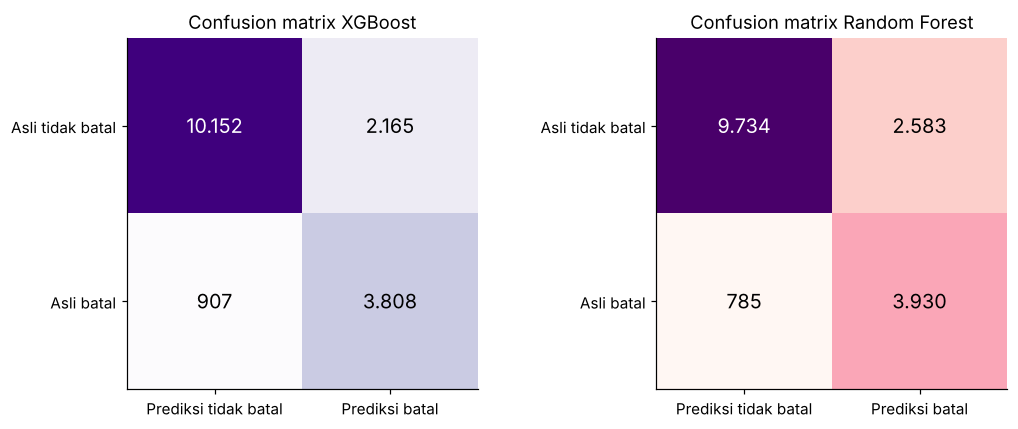

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (nama, m, warna) in zip(ax, [('XGBoost', m_xgb, 'Purples'), ('Random Forest', m_rf, 'RdPu')]):
    cm = np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]])
    a.imshow(cm, cmap=warna)
    for i in range(2):
        for j in range(2):
            a.text(j, i, ribuan(cm[i, j]), ha='center', va='center', fontsize=13,
                   color='white' if cm[i, j] > cm.max() / 2 else 'black')
    a.set_xticks([0, 1], ['Prediksi tidak batal', 'Prediksi batal'])
    a.set_yticks([0, 1], ['Asli tidak batal', 'Asli batal'])
    a.set_title(f'Confusion matrix {nama}')
plt.tight_layout(); plt.show()

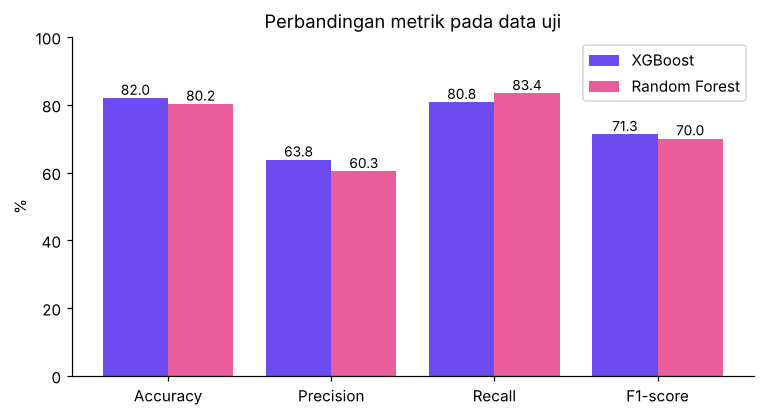

In [19]:
metrik = ['accuracy', 'precision', 'recall', 'f1']
x = np.arange(4)
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, [m_xgb[k] for k in metrik], 0.4, color=UNGU, label='XGBoost')
plt.bar(x + 0.2, [m_rf[k] for k in metrik], 0.4, color=PINK, label='Random Forest')
for i, k in enumerate(metrik):
    plt.text(i - 0.2, m_xgb[k] + 1, f'{m_xgb[k]:.1f}', ha='center', fontsize=9)
    plt.text(i + 0.2, m_rf[k] + 1, f'{m_rf[k]:.1f}', ha='center', fontsize=9)
plt.xticks(x, ['Accuracy', 'Precision', 'Recall', 'F1-score']); plt.ylabel('%'); plt.ylim(0, 100)
plt.title('Perbandingan metrik pada data uji'); plt.legend(); plt.show()

### 3.5 Pengaruh pre-pruning dan post-pruning

Percobaan berikut menunjukkan efek pruning pada **satu pohon keputusan** (komponen Random Forest) dan pada XGBoost.
Percobaan ini hanya ilustrasi; nilai parameter pruning model final sudah dipilih dengan data validasi di bagian 3.3.


In [20]:
Xb_l, Xb_u = b.transform(X_latih), b.transform(X_uji)
wbal = np.where(y_latih == 1, len(y_latih) / (2 * y_latih.sum()), len(y_latih) / (2 * (len(y_latih) - y_latih.sum())))
uji_pruning = []
for nama, prm in [('Tanpa pruning (kedalaman 40)', dict(max_depth=40, min_samples_leaf=1, min_samples_split=2)),
                  ('Pre-pruning (max_depth 12, min_samples_leaf 20)', dict(max_depth=12, min_samples_leaf=20, min_samples_split=40)),
                  ('Post-pruning (ccp_alpha 0,0001)', dict(max_depth=40, min_samples_leaf=1, min_samples_split=2, ccp_alpha=1e-4)),
                  ('Pre + post pruning', dict(max_depth=12, min_samples_leaf=20, min_samples_split=40, ccp_alpha=1e-4))]:
    p = DecisionTreeGini(**prm, seed=1).fit_binned(Xb_l, y_latih.astype(float), wbal, np.arange(len(y_latih)))
    ml = hitung_metrik(y_latih, p.predict_proba_binned(Xb_l) >= 0.5)
    mu = hitung_metrik(y_uji, p.predict_proba_binned(Xb_u) >= 0.5)
    uji_pruning.append(dict(Pohon=nama, Jumlah_daun=p.n_leaves(), Accuracy_latih=round(ml['accuracy'], 2),
                            Accuracy_uji=round(mu['accuracy'], 2), F1_uji=round(mu['f1'], 2)))
pd.DataFrame(uji_pruning)

,Pohon,Jumlah_daun,Accuracy_latih,Accuracy_uji,F1_uji
0,Tanpa pruning (kedalaman 40),12985,98.88,78.53,61.90
1,"Pre-pruning (max_depth 12, min_samples_leaf 20)",458,78.21,77.09,67.08
2,"Post-pruning (ccp_alpha 0,0001)",158,79.56,78.95,68.80
3,Pre + post pruning,110,77.85,77.23,67.33


In [21]:
uji_gamma = []
for g in [0.0, 1.0, 5.0]:
    prm = dict(PARAM_XGB, gamma=g)
    m = XGBoostManual(**prm).fit(X_latih, y_latih)
    n_daun = round(rata_daun(m), 1)
    mu = hitung_metrik(y_uji, m.predict_proba(X_uji) >= 0.5)
    uji_gamma.append(dict(gamma=g, Rata_rata_daun_per_pohon=n_daun, F1_uji=round(mu['f1'], 2)))
pd.DataFrame(uji_gamma)


,gamma,Rata_rata_daun_per_pohon,F1_uji
0,0.0,89.4,71.27
1,1.0,71.4,71.13
2,5.0,23.8,71.26


**Interpretasi:** pohon tanpa pruning hampir menghafal data latih (accuracy latih sangat tinggi) tetapi lebih buruk di data uji (overfitting).
Pre-pruning dan post-pruning mengurangi jumlah daun sehingga model lebih sederhana dan lebih stabil pada data baru.
Pada XGBoost, gamma yang lebih besar memangkas lebih banyak cabang. Dengan gamma 5, jumlah daun per pohon turun drastis
sementara F1 hampir tidak berubah, sehingga gamma 5 dipakai pada model final.


### 3.6 Pengaruh pembagian data (split)

Kedua model diuji dengan empat pembagian data menggunakan parameter terbaik yang sama.


In [22]:
uji_split = []
for nama_split, ts in [('90:10', 0.1), ('80:20', 0.2), ('70:30', 0.3), ('60:40', 0.4)]:
    il, iu = stratified_split(y, test_size=ts, seed=42)
    e = Encoder().fit(data.iloc[il])
    Xl, Xu = e.transform(data.iloc[il]), e.transform(data.iloc[iu])
    for nama_model, kelas, prm in [('XGBoost', XGBoostManual, PARAM_XGB), ('Random Forest', RandomForestManual, PARAM_RF)]:
        t = time.time(); m = kelas(**prm).fit(Xl, y[il]); dt = time.time() - t
        mt = hitung_metrik(y[iu], m.predict_proba(Xu) >= 0.5)
        uji_split.append(dict(Split=nama_split, Model=nama_model, Data_uji=len(iu), Accuracy=mt['accuracy'],
                              Precision=mt['precision'], Recall=mt['recall'], F1=mt['f1'], Detik=dt))
tabel_split = pd.DataFrame(uji_split).round(2)
tabel_split

,Split,Model,Data_uji,Accuracy,Precision,Recall,F1,Detik
0,90:10,XGBoost,8517,81.75,63.35,80.92,71.06,15.35
1,90:10,Random Forest,8517,78.84,57.98,85.67,69.15,15.33
2,80:20,XGBoost,17032,81.96,63.75,80.76,71.26,13.07
3,80:20,Random Forest,17032,80.23,60.34,83.35,70.00,14.58
4,70:30,XGBoost,25548,81.63,63.19,80.54,70.82,11.63
5,70:30,Random Forest,25548,79.34,58.85,84.33,69.32,12.96
6,60:40,XGBoost,34065,81.69,63.34,80.39,70.85,9.85
7,60:40,Random Forest,34065,79.94,59.89,83.38,69.71,11.44


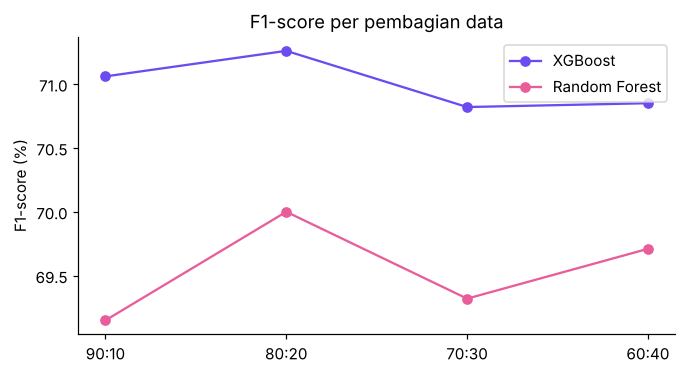

Kombinasi terbaik: XGBoost 80:20 | F1 71,26%


In [23]:
pv = tabel_split.pivot(index='Split', columns='Model', values='F1').loc[['90:10', '80:20', '70:30', '60:40']]
plt.figure(figsize=(7, 3.5))
plt.plot(pv.index, pv['XGBoost'], marker='o', color=UNGU, label='XGBoost')
plt.plot(pv.index, pv['Random Forest'], marker='o', color=PINK, label='Random Forest')
plt.ylabel('F1-score (%)'); plt.title('F1-score per pembagian data'); plt.legend(); plt.show()
terbaik_split = tabel_split.loc[tabel_split['F1'].idxmax()]
print('Kombinasi terbaik:', terbaik_split['Model'], terbaik_split['Split'], '| F1', persen(terbaik_split['F1']))

## 4. Evaluation: kenapa metrik ini dipakai

| Metode | Alasan dipakai |
|---|---|
| **Confusion matrix** | Melihat jenis kesalahan secara rinci. FN = tamu batal yang tidak terdeteksi (kamar kosong, hotel rugi). FP = tamu aman yang ditebak batal (berisiko jika hotel overbooking). |
| **Accuracy** | Ukuran umum, tetapi menyesatkan pada data tidak seimbang: menebak "tidak batal" terus sudah mendapat sekitar 72%. |
| **Precision** | Dari semua yang diprediksi batal, berapa yang benar batal. Penting agar hotel tidak salah menindak tamu yang aman. |
| **Recall** | Dari semua yang benar batal, berapa yang tertangkap. Penting agar pembatalan tidak lolos. |
| **F1-score** | Rata-rata harmonis precision dan recall. Dipakai sebagai **dasar memilih model terbaik** karena data tidak seimbang. |
| **Baseline** | Bukti bahwa model benar-benar lebih baik daripada aturan sederhana. |
| **Perbandingan split** | Bukti bahwa hasil model stabil dan tidak bergantung pada satu cara pembagian data. |

In [24]:
pemenang = 'XGBoost' if m_xgb['f1'] >= m_rf['f1'] else 'Random Forest'
print(f"F1 XGBoost       : {persen(m_xgb['f1'])}")
print(f"F1 Random Forest : {persen(m_rf['f1'])}")
print(f"F1 baseline terbaik: {persen(max(r['F1'] for r in hasil_baseline))}")
print('Model terbaik (F1 tertinggi):', pemenang)

F1 XGBoost       : 71,26%
F1 Random Forest : 70,00%
F1 baseline terbaik: 42,31%
Model terbaik (F1 tertinggi): XGBoost


## 5. Explainability: SHAP manual

Nilai SHAP dihitung dengan **metode permutasi Shapley**: untuk setiap reservasi, fitur dimasukkan satu per satu dalam urutan acak
ke sebuah baris latar (background). Selisih keluaran model saat sebuah fitur masuk adalah kontribusi fitur tersebut.
Hasilnya dirata-ratakan atas beberapa permutasi. Kolom One-Hot digabung kembali ke 21 fitur asalnya.

- Keluaran yang dijelaskan: **log-odds** untuk XGBoost dan **probabilitas** untuk Random Forest.
- Sampel: 200 data uji, 10 permutasi, background 1.000 data latih (sama dengan aplikasi).

In [25]:
nama_fitur = [g[0] for g in enc.groups]
latar = X_latih[np.random.default_rng(0).choice(len(X_latih), 1000, replace=False)]
phi_xgb = shap_permutasi(xgb.output, X_uji[:200], latar, enc.groups, n_perm=10)
phi_rf = shap_permutasi(rf.output, X_uji[:200], latar, enc.groups, n_perm=10)

def ke_persen(phi):
    v = np.abs(phi).mean(axis=0)
    return pd.Series(v / v.sum() * 100, index=nama_fitur).sort_values(ascending=False)

shap_xgb, shap_rf = ke_persen(phi_xgb), ke_persen(phi_rf)
pd.DataFrame({'XGBoost (%)': shap_xgb.round(1), 'Random Forest (%)': shap_rf.round(1)}).sort_values('XGBoost (%)', ascending=False).head(10)

,XGBoost (%),Random Forest (%)
required_car_parking_spaces,19.2,8.0
country,16.5,19.1
agent,11.4,16.1
lead_time,10.3,13.1
market_segment,9.7,8.4
total_of_special_requests,9.2,11.2
customer_type,5.1,5.8
adr,3.2,2.5
previous_bookings_not_canceled,2.7,1.8
arrival_date_month,2.3,1.2


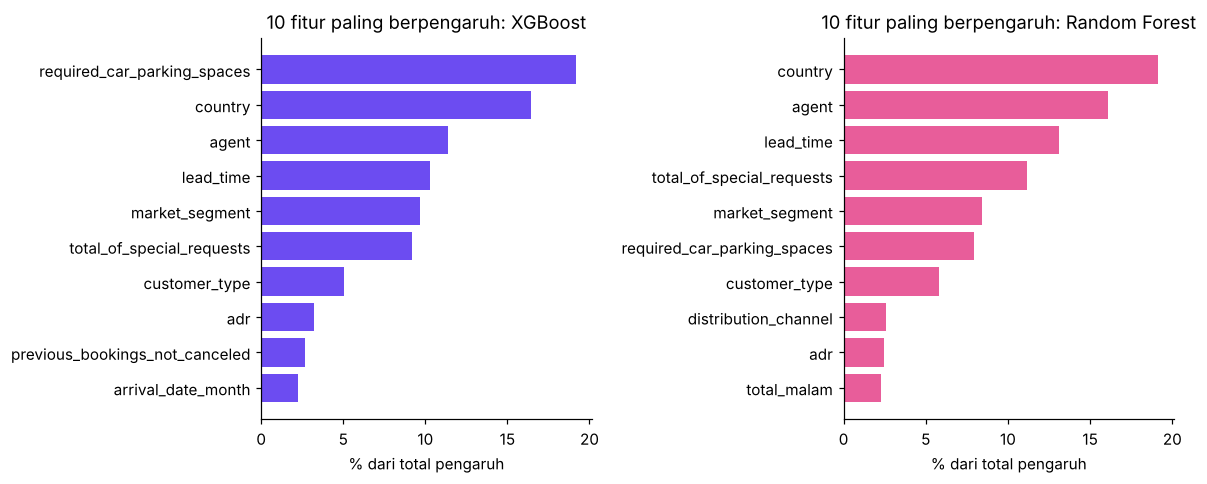

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (nama, s, warna) in zip(ax, [('XGBoost', shap_xgb, UNGU), ('Random Forest', shap_rf, PINK)]):
    top = s.head(10)[::-1]
    a.barh(top.index, top.values, color=warna)
    a.set_title(f'10 fitur paling berpengaruh: {nama}'); a.set_xlabel('% dari total pengaruh')
plt.tight_layout(); plt.show()

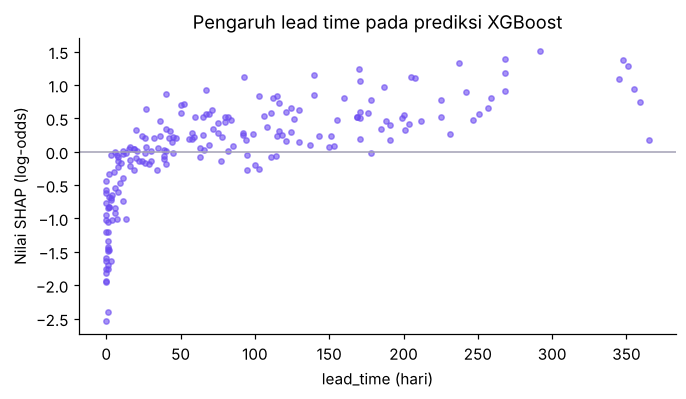

In [27]:
# Arah pengaruh lead time terhadap risiko batal (XGBoost)
j = nama_fitur.index('lead_time')
lt = data.iloc[idx_uji[:200]]['lead_time'].to_numpy()
plt.figure(figsize=(7, 3.5))
plt.scatter(lt, phi_xgb[:, j], s=12, color=UNGU, alpha=0.6)
plt.axhline(0, color=ABU, lw=1)
plt.xlabel('lead_time (hari)'); plt.ylabel('Nilai SHAP (log-odds)')
plt.title('Pengaruh lead time pada prediksi XGBoost'); plt.show()

In [28]:
# Penjelasan satu reservasi (lokal)
i = int(np.argmax(prob_xgb[:200]))
kontribusi = pd.Series(phi_xgb[i], index=nama_fitur).sort_values(key=np.abs, ascending=False).head(6)
print(f'Reservasi uji ke-{i}: probabilitas batal XGBoost = {persen(prob_xgb[i] * 100, 1)}, label asli = {y_uji[i]}')
print(kontribusi.round(3).to_string())

Reservasi uji ke-57: probabilitas batal XGBoost = 99,8%, label asli = 1
previous_cancellations            3.349
lead_time                         1.332
country                           1.041
total_malam                       0.270
previous_bookings_not_canceled    0.220
arrival_date_month               -0.133


**Interpretasi SHAP:** nilai positif menaikkan risiko batal, nilai negatif menurunkannya.
Hasil ini ditampilkan di aplikasi pada menu **Evaluasi**, dan SHAP per reservasi dipakai di menu **Prediksi** untuk menampilkan 3 alasan utama.

## 6. Deployment (tahap akhir CRISP-DM)

| Tahap | Isi |
|---|---|
| 1. Modularisasi | Fungsi dari notebook dipindah ke folder `backend/ml/`: `preprocessing.py`, `evaluasi.py`, `pohon_keputusan.py`, `random_forest.py`, `xgboost_manual.py`, `shap_manual.py`; parameter terbaik ke `backend/ml/latih_model.py` |
| 2. Model final | Kedua model dilatih ulang dan disimpan sebagai `backend/models/model_xgboost.pkl` dan `model_random_forest.pkl` (pickle), beserta `evaluasi.json`, dengan perintah `python ml/latih_model.py` |
| 3. Backend API | Flask menyediakan endpoint unggah data, preprocessing, dashboard, prediksi satu reservasi, dan evaluasi. Model hanya dimuat, tidak dilatih ulang di aplikasi |
| 4. Penyimpanan | Supabase: tabel `dataset` (PostgreSQL, dibuat dari `schema.sql`) dan bucket Storage `datasets` untuk file CSV. Tanpa Supabase, aplikasi memakai SQLite lokal |
| 5. Frontend | Vue 3 + Tailwind: menu Dashboard BI, Unggah Data, Prediksi, Evaluasi |
| 6. Hosting backend | Vercel, project `backend` (preset Other, entry `api/index.py`), environment `SUPABASE_URL`, `SUPABASE_SERVICE_KEY`, `SUPABASE_BUCKET` |
| 7. Hosting frontend | Vercel, project `frontend` (preset Vite), environment `VITE_API_URL` berisi alamat backend |
| 8. Pengujian | Pengujian black-box tiap menu pada alamat Vercel: unggah data, preprocessing, prediksi, dan evaluasi |


In [29]:
ringkasan = dict(
    param_rf=PARAM_RF, param_xgb=PARAM_XGB,
    metrik_uji=dict(xgboost=m_xgb, random_forest=m_rf),
    baseline=hasil_baseline, split=uji_split,
    shap_xgboost=shap_xgb.round(2).to_dict(), shap_random_forest=shap_rf.round(2).to_dict())
(HASIL / 'ringkasan_hasil.json').write_text(json.dumps(ringkasan, indent=2, default=float))
tabel_split.to_csv(HASIL / 'perbandingan_split.csv', index=False)
data.to_csv(HASIL / 'data_bersih.csv', index=False)
print('Hasil disimpan ke folder hasil/')

Hasil disimpan ke folder hasil/


## Kesimpulan

1. Data Hotel Booking dibersihkan dari 119.390 menjadi 85.162 reservasi (27,7% batal) dan diubah menjadi 68 fitur numerik dengan encoding manual.
2. Random Forest dan XGBoost berhasil diimplementasikan secara manual. Model final memakai pre-pruning (`max_depth`, `min_samples_split`, `min_samples_leaf`, `min_child_weight`)
   dan post-pruning (`ccp_alpha` = 0,00005 pada Random Forest, `gamma` = 5 pada XGBoost) yang dipilih dengan data validasi.
3. Hasil pada 17.032 data uji:

| Model | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| **XGBoost (terbaik)** | **81,96%** | **63,75%** | **80,76%** | **71,26%** |
| Random Forest | 80,23% | 60,34% | 83,35% | 70,00% |
| Baseline terbaik: pohon kedalaman 3 | 74,56% | 56,83% | 33,70% | 42,31% |

4. XGBoost dipilih sebagai model terbaik karena F1-score-nya paling tinggi. F1 dipakai karena data tidak seimbang. Kedua model jauh mengalahkan baseline.
5. Selisih F1 data latih dan data uji hanya 1,52 poin (XGBoost) dan 3,21 poin (Random Forest), sehingga model **good fit**:
   tidak overfitting dan tidak underfitting. Hasil juga stabil pada pembagian data 90:10 sampai 60:40 (F1 XGBoost 70,82% sampai 71,26%).
6. SHAP manual menunjukkan fitur yang paling memengaruhi pembatalan adalah tempat parkir, negara asal, agen, lead time, dan segmen pasar,
   sehingga hotel dapat menyusun tindakan pencegahan.
7. Model diterapkan ke aplikasi web HotelGuard (Flask + Vue + Supabase, di-hosting di Vercel).
